# CSCI461 Assignment 1: SMS Spam Collection
Integrated team notebook: preprocessing, text analysis, classification and K-Means.



Team names and student IDs: 
AHMED AYMAN ELSAYED 221001987
SALMA MAHMOUD MOHAMED 231001229
AMINA MOHSEN 231002112
AMRO AYMAN ABAARY 231002716

In [1]:
from pathlib import Path
import os
from IPython.display import display, Markdown

PROJECT = Path.cwd()
if not (PROJECT / "data/dataset.csv").exists():
    PROJECT = PROJECT.parent
if not (PROJECT / "data/dataset.csv").exists():
    raise FileNotFoundError("Open notebook/analysis.ipynb from the bd-a1 project.")
os.chdir(PROJECT)
OUTPUT = PROJECT / "output"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
print("Project:", PROJECT)
print("Persistent output:", OUTPUT)


Project: /home/jovyan/bd-a1
Persistent output: /home/jovyan/bd-a1/output


## Part 1: Data preprocessing and analysis
Source: the team's `analysis.ipynb`.
Each row is an SMS message. `message` is the original text and `label` is ham or spam.
The original file has no numerical columns; numerical text features are created below.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Load Dataset
df = pd.read_csv("data/dataset.csv")

# Display first 5 rows
df.head()


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Columns:", df.columns.tolist())
print("Data types:")
print(df.dtypes)


Columns: ['label', 'message']
Data types:
label      str
message    str
dtype: object


In [4]:
# Display first 5 rows
df.head()

# Dataset dimensions
print("Shape:", df.shape)

# Dataset information
df.info()

# Statistical description
df.describe(include='all')


Shape: (5572, 2)
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [5]:
print("Shape before cleaning:", df.shape)
print("Missing values:")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
raw_label_counts = df["label"].value_counts()

# Labels and text are required for this task. No values are missing in this file.
# Removing exact duplicate rows also prevents the same SMS appearing in train and test.
df = df.dropna(subset=["label", "message"]).drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print(df["label"].value_counts())


Shape before cleaning: (5572, 2)
Missing values:
label      0
message    0
dtype: int64
Duplicate rows: 403
Shape after cleaning: (5169, 2)
Remaining duplicates: 0
label
ham     4516
spam     653
Name: count, dtype: int64


Missing labels/text cannot support a labelled SMS analysis, so those rows would be
dropped; none are missing in the supplied file. Exact duplicates are removed, rather
than counting identical messages repeatedly. All subsequent sections use this same
deduplicated dataset. The file should have 5,572 original rows, 403 duplicates and
5,169 rows after deduplication, before any empty cleaned text is filtered for modeling.


In [6]:
# Using loc (select rows by index labels)
print("Using loc:")
print(df.loc[0:4, ['label', 'message']])

# Using iloc (select rows and columns by position)
print("Using iloc:")
print(df.iloc[0:5, 0:2])

# Using np.r_ to combine row indices
selected_rows = np.r_[0:3, 10:13]

print("Using np.r_:")
print(df.iloc[selected_rows])


Using loc:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Using iloc:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Using np.r_:
   label                                            message
0    ham  Go until jurong point, crazy.. Available only ...
1    ham                      Ok lar... Joking wif u oni...
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...
10   ham  I'm go

In [7]:
# loc can also select rows using a meaningful condition.
display(df.loc[df["label"] == "spam", ["label", "message"]].head())


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."


In [8]:
# Transformation 1: Convert text to lowercase
df['lowercase_message'] = df['message'].str.lower()

# Transformation 2: Remove punctuation
df['no_punctuation'] = df['lowercase_message'].apply(
    lambda x: re.sub(r'[^\w\s]', '', x)
)

# Transformation 3: Remove extra spaces
df['cleaned_message'] = df['no_punctuation'].apply(
    lambda x: re.sub(r'\s+', ' ', x).strip()
)

# Display results
df[['message', 'lowercase_message',
    'no_punctuation', 'cleaned_message']].head()


,message,lowercase_message,no_punctuation,cleaned_message
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",go until jurong point crazy available only in ...,go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,nah i dont think he goes to usf he lives aroun...


In [9]:
simple_random = df.sample(
    frac=0.20,
    random_state=42
)

print("Simple Random Sampling:")
print(simple_random['label'].value_counts(normalize=True) * 100)


Simple Random Sampling:
label
ham     86.460348
spam    13.539652
Name: proportion, dtype: float64


In [10]:
stratified_sample = df.groupby(
    'label',
    group_keys=False
).sample(
    frac=0.20,
    random_state=42
)

print("Stratified Sampling:")
print(stratified_sample['label'].value_counts(normalize=True) * 100)


Stratified Sampling:
label
ham     87.330754
spam    12.669246
Name: proportion, dtype: float64


In [11]:
# Create message length
df['message_length'] = df['message'].apply(len)

# Divide data into 5 clusters
df['cluster'] = pd.qcut(
    df['message_length'],
    q=5,
    labels=False,
    duplicates='drop'
)

# Randomly select 2 clusters
np.random.seed(42)

selected_clusters = np.random.choice(
    df['cluster'].unique(),
    size=2,
    replace=False
)

# Select all rows from selected clusters
cluster_sample = df[
    df['cluster'].isin(selected_clusters)
]

print("Selected Clusters:", selected_clusters)

print("Cluster Sampling:")
print(cluster_sample['label'].value_counts(normalize=True) * 100)


Selected Clusters: [0 1]
Cluster Sampling:
label
ham     99.182692
spam     0.817308
Name: proportion, dtype: float64


        Original  Simple Random  Stratified    Cluster
label                                                 
ham    87.366996      86.460348   87.330754  99.182692
spam   12.633004      13.539652   12.669246   0.817308


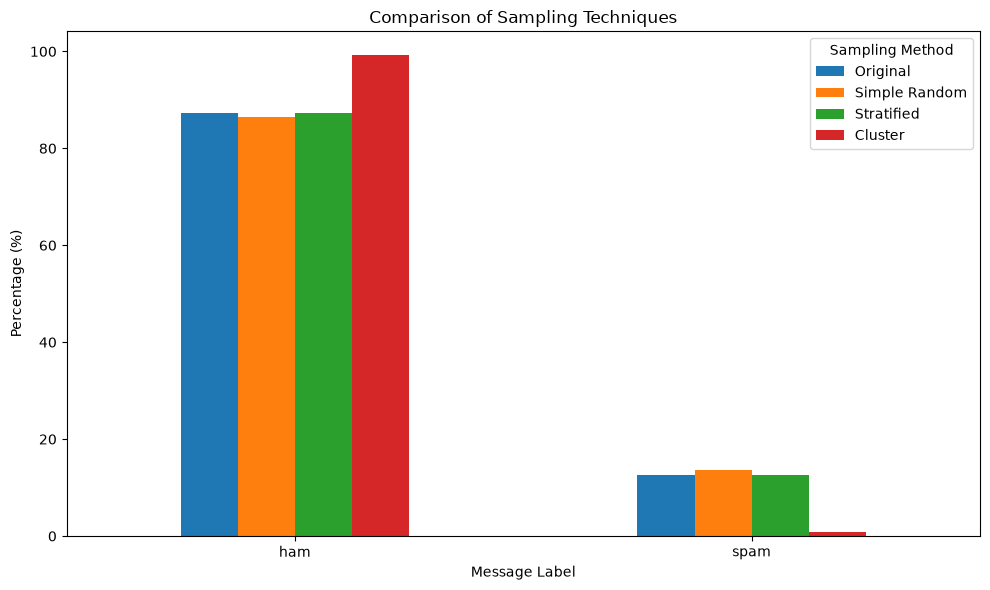

In [12]:
sampling_comparison = pd.DataFrame({
    'Original': df['label'].value_counts(normalize=True) * 100,
    'Simple Random': simple_random['label'].value_counts(normalize=True) * 100,
    'Stratified': stratified_sample['label'].value_counts(normalize=True) * 100,
    'Cluster': cluster_sample['label'].value_counts(normalize=True) * 100
})

print(sampling_comparison)

# Visualize comparison
sampling_comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Comparison of Sampling Techniques')
plt.ylabel('Percentage (%)')
plt.xlabel('Message Label')
plt.xticks(rotation=0)
plt.legend(title='Sampling Method')
plt.tight_layout()
plt.savefig(FIGURES / "sampling_comparison.png", dpi=150)
plt.show()


In [13]:
# Feature 1: Character Count
df['char_count'] = df['message'].apply(len)

# Feature 2: Word Count
df['word_count'] = df['message'].apply(
    lambda x: len(x.split())
)

# Feature 3: Average Word Length
df['avg_word_length'] = df['message'].apply(
    lambda x: np.mean([len(word) for word in x.split()])
    if len(x.split()) > 0 else 0
)

# Feature 4: Digit Count
df['digit_count'] = df['message'].apply(
    lambda x: sum(char.isdigit() for char in x)
)

# Display the new features
df[[
    'message',
    'char_count',
    'word_count',
    'avg_word_length',
    'digit_count'
]].head()


,message,char_count,word_count,avg_word_length,digit_count
0,"Go until jurong point, crazy.. Available only ...",111,20,4.600000,0
1,Ok lar... Joking wif u oni...,29,6,4.000000,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,4.571429,25
3,U dun say so early hor... U c already then say...,49,11,3.545455,0
4,"Nah I don't think he goes to usf, he lives aro...",61,13,3.769231,0


                 char_count  word_count  avg_word_length  digit_count  \
char_count         1.000000    0.973858         0.084239     0.378848   
word_count         0.973858    1.000000        -0.067163     0.283588   
avg_word_length    0.084239   -0.067163         1.000000     0.229609   
digit_count        0.378848    0.283588         0.229609     1.000000   
label_numeric      0.379791    0.283920         0.242217     0.836894   

                 label_numeric  
char_count            0.379791  
word_count            0.283920  
avg_word_length       0.242217  
digit_count           0.836894  
label_numeric         1.000000  


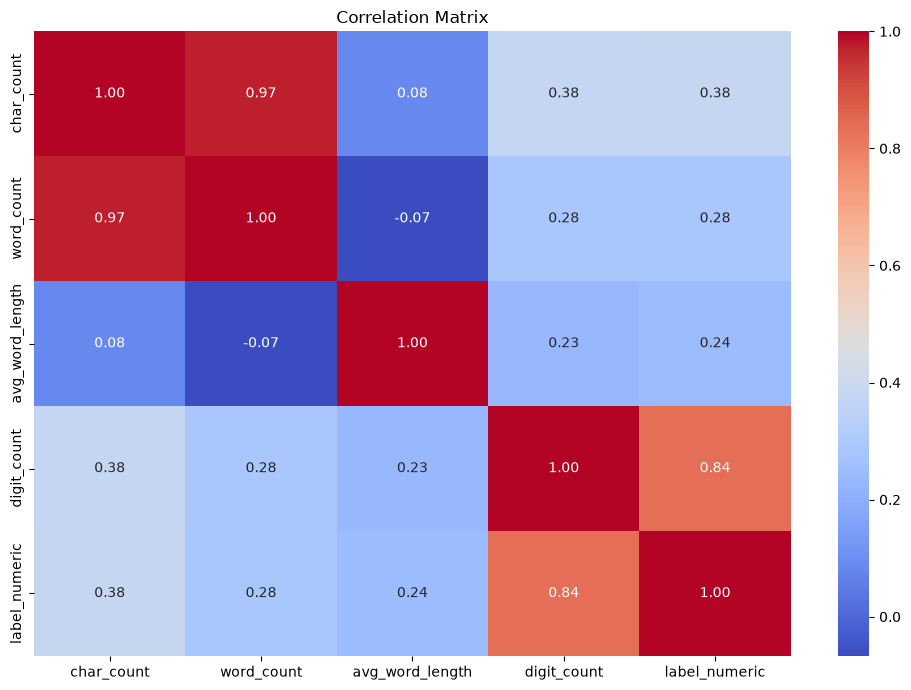

In [14]:
# Convert label into numerical values
df['label_numeric'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

# Select numerical features
numerical_features = [
    'char_count',
    'word_count',
    'avg_word_length',
    'digit_count',
    'label_numeric'
]

# Calculate correlation matrix
correlation_matrix = df[numerical_features].corr()

print(correlation_matrix)

# Visualize correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig(FIGURES / "correlation_heatmap.png", dpi=150)
plt.show()


In [15]:
pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape, dtype=bool), k=1)
).stack()

strongest = pairs.abs().idxmax()
weakest = pairs.abs().idxmin()

print(f"Strongest pair: {strongest}, r={pairs[strongest]:.3f}")
print(f"Weakest pair: {weakest}, r={pairs[weakest]:.3f}")

Strongest pair: ('char_count', 'word_count'), r=0.974
Weakest pair: ('word_count', 'avg_word_length'), r=-0.067


**Sampling:** simple random sampling chooses individual messages without using labels;
stratified sampling samples within ham/spam groups and preserves their proportions
approximately (rounding affects small groups). Cluster sampling selects entire groups:
here the groups are five artificial message-length bins, and two bins are selected.
These artificial groups are a demonstration, not naturally occurring collection sites;
length-based groups can distort the spam proportion. The cluster sample is about 40%
of the rows, while the other samples are about 20%, so sampling fractions also differ.

**Correlation:** character and word counts tend to increase together because longer
messages contain more words. Relationships with `label_numeric` describe association
with spam in this dataset, not a cause of spam. The printed strongest/weakest pairs
identify the actual relationships in this run. Correlation does not imply causation;
shared measurement definitions, confounding and sampling may explain an association.


In [16]:
print("Final Dataset Shape:", df.shape)

print("\nFinal Dataset Information:")
df.info()

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())


Final Dataset Shape: (5169, 12)

Final Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5169 entries, 0 to 5168
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   label              5169 non-null   str    
 1   message            5169 non-null   str    
 2   lowercase_message  5169 non-null   str    
 3   no_punctuation     5169 non-null   str    
 4   cleaned_message    5169 non-null   str    
 5   message_length     5169 non-null   int64  
 6   cluster            5169 non-null   int64  
 7   char_count         5169 non-null   int64  
 8   word_count         5169 non-null   int64  
 9   avg_word_length    5169 non-null   float64
 10  digit_count        5169 non-null   int64  
 11  label_numeric      5169 non-null   int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 2.0 MB

First 5 Rows:


,label,message,lowercase_message,no_punctuation,cleaned_message,message_length,cluster,char_count,word_count,avg_word_length,digit_count,label_numeric
0,ham,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",go until jurong point crazy available only in ...,go until jurong point crazy available only in ...,111,3,111,20,4.600000,0,0
1,ham,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni,29,0,29,6,4.000000,0,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,free entry in 2 a wkly comp to win fa cup fina...,155,4,155,28,4.571429,25,1
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,u dun say so early hor u c already then say,u dun say so early hor u c already then say,49,2,49,11,3.545455,0,0
4,ham,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,nah i dont think he goes to usf he lives aroun...,61,2,61,13,3.769231,0,0



Missing Values:
label                0
message              0
lowercase_message    0
no_punctuation       0
cleaned_message      0
message_length       0
cluster              0
char_count           0
word_count           0
avg_word_length      0
digit_count          0
label_numeric        0
dtype: int64


## Part 2: Text analysis
Source: the team's `Text_Analysis_-3.ipynb`.
Google Colab upload/unzip cells have been removed. This section continues with the
deduplicated `df` from Part 1; it does not reload the raw dataset.


## 1. Text Cleaning


In [17]:
import html
import re

def clean_text(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r"(?<=[a-z])'(?=[a-z])", '', text)
    text = re.sub(r'\d+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_text'] = df['message'].fillna('').apply(clean_text)

df[['message', 'cleaned_text']].head(10)


,message,cleaned_text
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...


## 2. Tokenization and Basic Statistics


In [18]:
df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())

total_tokens = sum(df['tokens'].apply(len))

all_words = [word for tokens in df['tokens'] for word in tokens]

unique_words = set(all_words)

average_words = total_tokens / len(df)

print("Total Tokens:", total_tokens)
print("Unique Words:", len(unique_words))
print("Average Words per Record:", round(average_words, 2))


Total Tokens: 77732
Unique Words: 7805
Average Words per Record: 15.04


## 3. Most Frequent Words


In [19]:
from collections import Counter

word_counts = Counter(all_words)

top_20 = word_counts.most_common(20)

top_20_df = pd.DataFrame(top_20, columns=['Word', 'Frequency'])

top_20_df


,Word,Frequency
0,i,2267
1,to,2080
2,you,2063
3,a,1325
4,the,1249
5,u,1072
6,and,930
7,in,835
8,is,799
9,me,758


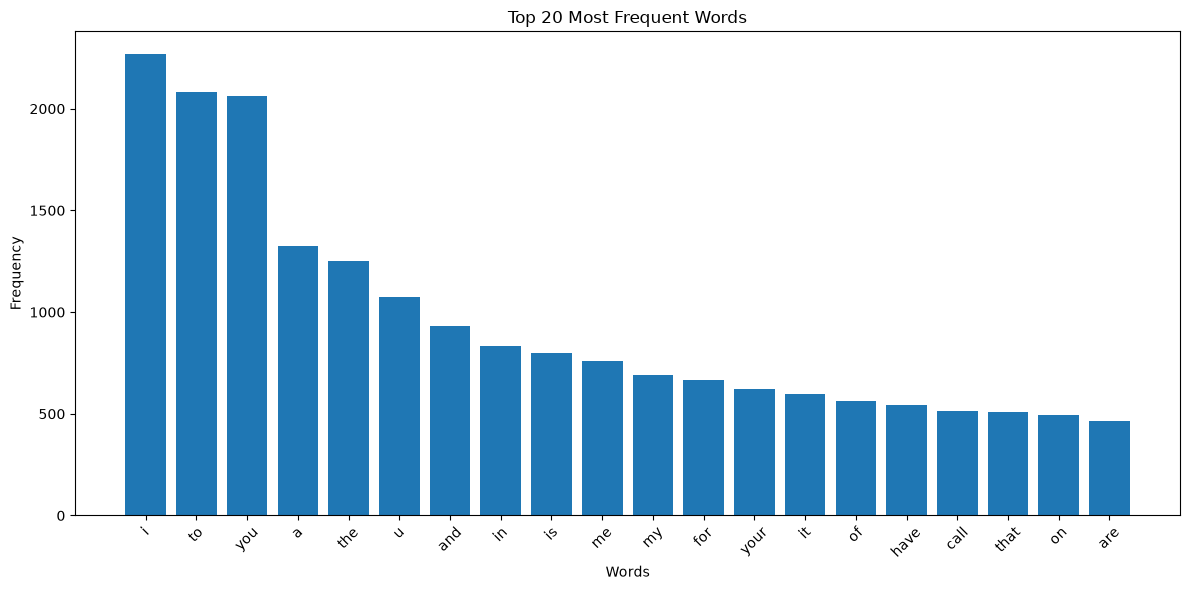

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(top_20_df['Word'], top_20_df['Frequency'])

plt.title('Top 20 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('output/figures/top_20_words.png')
plt.show()


## 4. Spam vs Ham Comparison


In [21]:
df['text_length'] = df['cleaned_text'].apply(len)
df['cleaned_word_count'] = df['tokens'].apply(len)

group_comparison = df.groupby('label').agg(
    average_text_length=('text_length', 'mean'),
    average_word_count=('cleaned_word_count', 'mean')
)

group_comparison


,average_text_length,average_word_count
label,,
ham,66.059566,14.007529
spam,112.437979,22.165391


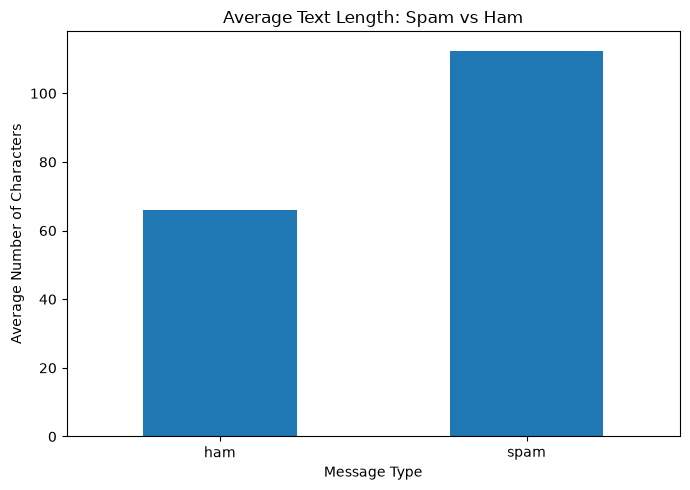

In [22]:
plt.figure(figsize=(7, 5))

group_comparison['average_text_length'].plot(kind='bar')

plt.title('Average Text Length: Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Average Number of Characters')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('output/figures/average_text_length.png')
plt.show()


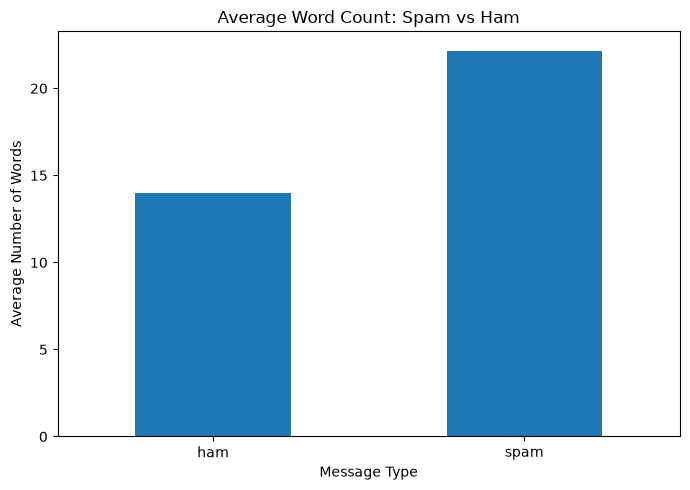

In [23]:
plt.figure(figsize=(7, 5))

group_comparison['average_word_count'].plot(kind='bar')

plt.title('Average Word Count: Spam vs Ham')
plt.xlabel('Message Type')
plt.ylabel('Average Number of Words')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig('output/figures/average_word_count.png')
plt.show()


## 5. Top 10 Words by Message Type


In [24]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

ham_words = [
    word for tokens in df[df['label'] == 'ham']['tokens']
    for word in tokens
    if word not in ENGLISH_STOP_WORDS
]

spam_words = [
    word for tokens in df[df['label'] == 'spam']['tokens']
    for word in tokens
    if word not in ENGLISH_STOP_WORDS
]

ham_top_10 = Counter(ham_words).most_common(10)
spam_top_10 = Counter(spam_words).most_common(10)

print("Ham Top 10:", ham_top_10)
print("Spam Top 10:", spam_top_10)


Ham Top 10: [('u', 925), ('im', 448), ('just', 282), ('ok', 256), ('dont', 252), ('got', 228), ('know', 226), ('like', 224), ('good', 217), ('come', 215)]
Spam Top 10: [('free', 197), ('p', 158), ('u', 147), ('txt', 138), ('ur', 119), ('stop', 116), ('mobile', 111), ('text', 108), ('claim', 96), ('reply', 96)]


## 6. Stop-word Removal Comparison


In [25]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

filtered_words = [
    word for word in all_words
    if word not in ENGLISH_STOP_WORDS
]

filtered_counts = Counter(filtered_words)

top_20_no_stopwords = pd.DataFrame(
    filtered_counts.most_common(20),
    columns=['Word', 'Frequency']
)

top_20_no_stopwords


,Word,Frequency
0,u,1072
1,im,463
2,just,350
3,ur,322
4,dont,269
5,ok,261
6,free,253
7,know,244
8,like,236
9,got,234


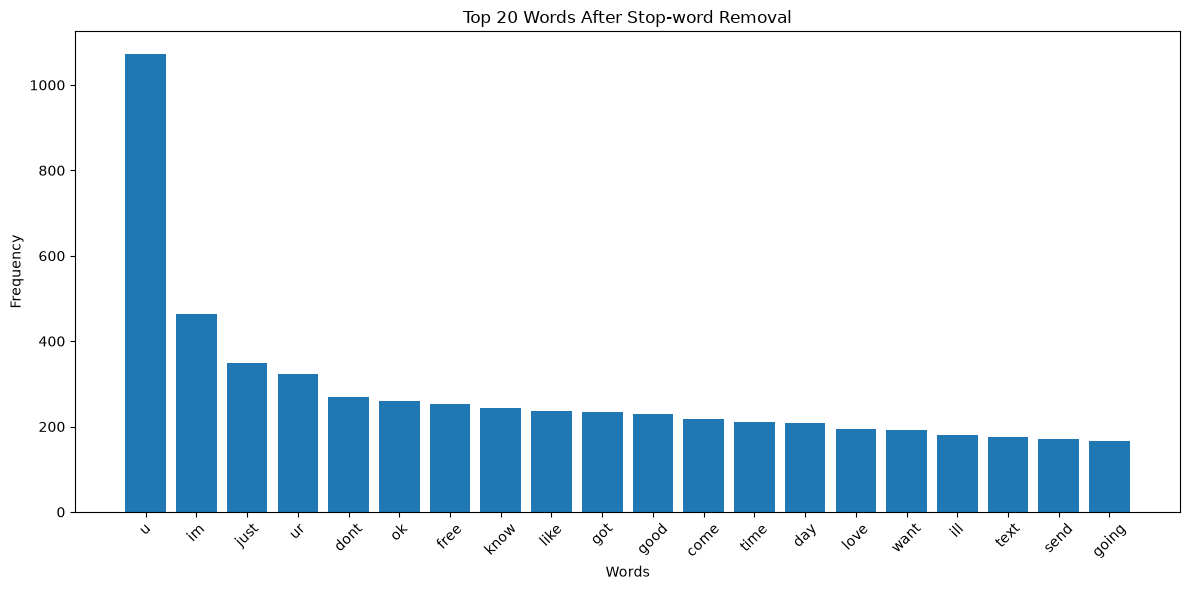

In [26]:
plt.figure(figsize=(12, 6))
plt.bar(top_20_no_stopwords['Word'], top_20_no_stopwords['Frequency'])

plt.title('Top 20 Words After Stop-word Removal')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('output/figures/top_20_words_without_stopwords.png')
plt.show()


## 7. Save Cleaned Dataset


In [27]:
df.to_csv(OUTPUT / "cleaned_data.csv", index=False)
print("Saved:", OUTPUT / "cleaned_data.csv")


Saved: /home/jovyan/bd-a1/output/cleaned_data.csv


### Five text insights based on this run
Numbers below are calculated from the integrated, deduplicated data, so the evidence
stays aligned with the notebook outputs rather than an older Colab execution.


In [28]:
counts = df["label"].value_counts()
ham_length = group_comparison.loc["ham", "average_text_length"]
spam_length = group_comparison.loc["spam", "average_text_length"]
ham_words_avg = group_comparison.loc["ham", "average_word_count"]
spam_words_avg = group_comparison.loc["spam", "average_word_count"]
spam_examples = ", ".join(word for word, count in spam_top_10)
ham_examples = ", ".join(word for word, count in ham_top_10)
insights = f"""
1. **Observation:** ham is the majority class.
   **Evidence:** {counts['ham']:,} ham and {counts['spam']:,} spam messages.
   **Interpretation:** accuracy should be considered alongside spam precision and recall.

2. **Observation:** average cleaned message lengths differ between the groups.
   **Evidence:** spam = {spam_length:.2f} characters; ham = {ham_length:.2f}.
   **Interpretation:** this is consistent with different communication styles, but length
   alone cannot reliably identify spam.

3. **Observation:** average cleaned word counts differ between the groups.
   **Evidence:** spam = {spam_words_avg:.2f} words; ham = {ham_words_avg:.2f}.
   **Interpretation:** promotional and personal messages use different amounts of text.

4. **Observation:** spam has recurring high-frequency vocabulary after stop-word removal.
   **Evidence:** its top ten words are {spam_examples}.
   **Interpretation:** these words suggest promotional or reply-request language;
   their presence alone is not proof that a message is spam.

5. **Observation:** ham has a different frequent-word profile.
   **Evidence:** its top ten words are {ham_examples}.
   **Interpretation:** the vocabulary is consistent with everyday conversation and can
   help explain why text features distinguish the two labels in this dataset.
"""
display(Markdown(insights))
(OUTPUT / "text_insights.md").write_text(insights, encoding="utf-8")



1. **Observation:** ham is the majority class.
   **Evidence:** 4,516 ham and 653 spam messages.
   **Interpretation:** accuracy should be considered alongside spam precision and recall.

2. **Observation:** average cleaned message lengths differ between the groups.
   **Evidence:** spam = 112.44 characters; ham = 66.06.
   **Interpretation:** this is consistent with different communication styles, but length
   alone cannot reliably identify spam.

3. **Observation:** average cleaned word counts differ between the groups.
   **Evidence:** spam = 22.17 words; ham = 14.01.
   **Interpretation:** promotional and personal messages use different amounts of text.

4. **Observation:** spam has recurring high-frequency vocabulary after stop-word removal.
   **Evidence:** its top ten words are free, p, u, txt, ur, stop, mobile, text, claim, reply.
   **Interpretation:** these words suggest promotional or reply-request language;
   their presence alone is not proof that a message is spam.

5. **Observation:** ham has a different frequent-word profile.
   **Evidence:** its top ten words are u, im, just, ok, dont, got, know, like, good, come.
   **Interpretation:** the vocabulary is consistent with everyday conversation and can
   help explain why text features distinguish the two labels in this dataset.


1316

## Part 3: Machine learning
Source: the team's `machine_learning.ipynb`.
Model settings, TF-IDF, the stratified split, two classifiers, the K-Means candidate
experiment and the final k=2 choice are retained. To integrate the project, this section
uses the shared `cleaned_text` from Part 2 rather than cleaning the raw file again.
The shared cleaner removes numbers and URLs; this may remove useful spam signals.
Results may differ from the separate notebook, which kept numbers in its own cleaner.


In [29]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             silhouette_score, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import Normalizer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("output", exist_ok=True)   # bind-mounted to the host in Docker


In [30]:
model_df = df.copy()
model_df = model_df[model_df["cleaned_text"].str.len() > 0].reset_index(drop=True)
model_df["y"] = (model_df["label"] == "spam").astype(int)
print("Rows available for modeling:", len(model_df))
print("Empty cleaned-text rows excluded:", len(df) - len(model_df))
print(model_df["label"].value_counts().to_string())
# Preserve the full cleaned analysis table for the required cleaned_data.csv.
analysis_df = df
df = model_df


Rows available for modeling: 5166
Empty cleaned-text rows excluded: 3
label
ham     4513
spam     653


# Part 1: Supervised Classification


## 1.1 Train / Test split
An **80/20 stratified split** is used. The classes are imbalanced (spam is a small minority), so stratification keeps the same spam ratio in both sets.


In [31]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["cleaned_text"], df["y"], test_size=0.20, stratify=df["y"], random_state=RANDOM_STATE)

print("Train:", X_train_txt.shape[0], "| Test:", X_test_txt.shape[0])
print("Spam ratio train: %.2f%% | test: %.2f%%" % (y_train.mean()*100, y_test.mean()*100))


Train: 4132 | Test: 1034
Spam ratio train: 12.63% | test: 12.67%


## 1.2 TF-IDF features
TF-IDF is **fit on the training set only** (no data leakage) and then applied to the test set. Unigrams + bigrams, English stop-words removed, words appearing in fewer than 2 messages ignored.


In [32]:
tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)
X_test  = tfidf.transform(X_test_txt)
print("TF-IDF matrix (train):", X_train.shape, "| (test):", X_test.shape)


TF-IDF matrix (train): (4132, 5157) | (test): (1034, 5157)


## 1.3 Train the models
Two models are compared: **Multinomial Naive Bayes** (fast, classic for text) and **Logistic Regression** (with `class_weight="balanced"` to compensate for the imbalance).


In [33]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
}

rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    rows.append({"Model": name,
                 "Accuracy":  accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall":    recall_score(y_test, p),
                 "F1-score":  f1_score(y_test, p)})

results = pd.DataFrame(rows).set_index("Model").round(4)
results.to_csv("output/classification_metrics.csv")
results


,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.9855,0.9915,0.8931,0.9398
Logistic Regression,0.9797,0.9167,0.9237,0.9202


Precision, Recall and F1 are computed for the **spam** class (positive class = 1), since that is the class we care about detecting.


In [34]:
best_name = results["F1-score"].idxmax()
print("Best model by F1-score:", best_name)
print()
print(classification_report(y_test, preds[best_name], target_names=["ham", "spam"], digits=4))


Best model by F1-score: Multinomial Naive Bayes

              precision    recall  f1-score   support

         ham     0.9847    0.9989    0.9918       903
        spam     0.9915    0.8931    0.9398       131

    accuracy                         0.9855      1034
   macro avg     0.9881    0.9460    0.9658      1034
weighted avg     0.9856    0.9855    0.9852      1034



## 1.4 Confusion matrices


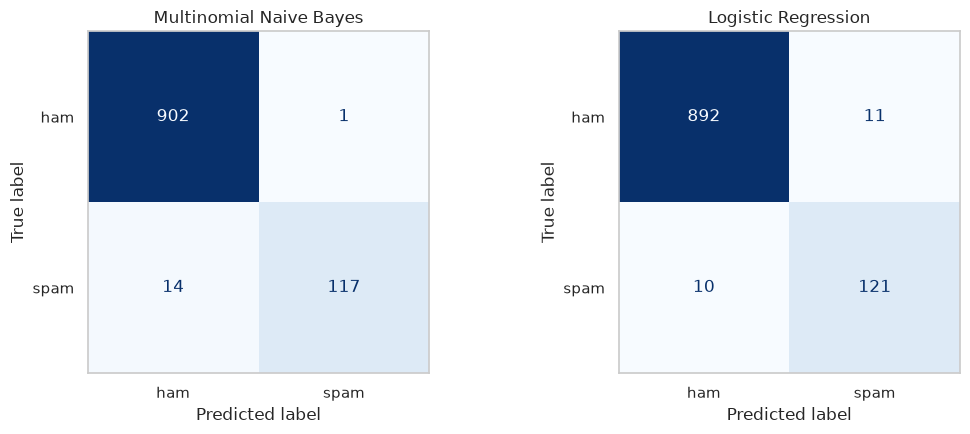

Multinomial Naive Bayes: TN=902  FP=1  FN=14  TP=117
Logistic Regression: TN=892  FP=11  FN=10  TP=121


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.savefig("output/figures/confusion_matrices.png", dpi=150); plt.show()

for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    print(f"{name}: TN={tn}  FP={fp}  FN={fn}  TP={tp}")


## 1.5 Most informative words and error analysis


In [36]:
lr = models["Logistic Regression"]
terms = np.array(tfidf.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top = pd.DataFrame({"Top SPAM indicators": terms[order[::-1][:15]], "Top HAM indicators": terms[order[:15]]})
display(top)

# Misclassified test messages for the best model
test_df = df.loc[X_test_txt.index, ["message", "label"]].copy()
test_df["predicted"] = np.where(preds[best_name] == 1, "spam", "ham")
errors = test_df[test_df["label"] != test_df["predicted"]]
print(f"{len(errors)} misclassified messages by {best_name}:")
pd.set_option("display.max_colwidth", 140)
errors.head(10)


,Top SPAM indicators,Top HAM indicators
0,txt,ok
1,free,ill
2,mobile,im
3,text,come
4,reply,home
5,claim,da
6,stop,lor
7,new,way
8,prize,got
9,won,thats


15 misclassified messages by Multinomial Naive Bayes:


,message,label,predicted
1262,Your daily text from me – a favour this time,ham,spam
4497,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,spam,ham
2907,"Hi babe its Jordan, how r u? Im home from abroad and lonely, text me back if u wanna chat xxSP visionsms.com Text stop to stopCost 150p ...",spam,ham
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,spam,ham
3947,Missed call alert. These numbers called but left no message. 07008009200,spam,ham
4986,dating:i have had two of these. Only started after i sent a text to talk sport radio last week. Any connection do you think or coincidence?,spam,ham
4183,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,spam,ham
3741,ringtoneking 84484,spam,ham
2179,88066 FROM 88066 LOST 3POUND HELP,spam,ham
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",spam,ham


In [37]:
(OUTPUT / "model_metrics.txt").write_text(
    "Supervised SMS classification\n"
    + f"Training rows: {len(y_train)}; test rows: {len(y_test)}\n"
    + "Positive class: spam (1)\n\n"
    + results.to_string() + "\n\n"
    + f"Best model by spam F1: {best_name}\n\n"
    + classification_report(y_test, preds[best_name],
        target_names=["ham", "spam"], digits=4)
    + "\nLimitations: one train/test split; TF-IDF lacks semantic context; "
    + "the shared cleaner removes numbers/URLs that can indicate spam.\n",
    encoding="utf-8"
)
tn, fp, fn, tp = confusion_matrix(y_test, preds[best_name]).ravel()
print(f"Best by spam F1: {best_name}")
print(f"Correct ham: {tn}; false alarms: {fp}; missed spam: {fn}; caught spam: {tp}")
print("Accuracy of always predicting ham:", round((y_test == 0).mean(), 4))
print("Limitations: one split, limited vocabulary/context, and removed numerical signals.")


Best by spam F1: Multinomial Naive Bayes
Correct ham: 902; false alarms: 1; missed spam: 14; caught spam: 117
Accuracy of always predicting ham: 0.8733
Limitations: one split, limited vocabulary/context, and removed numerical signals.


# Part 2: K-Means Clustering


## 2.1 Numerical representation
K-Means uses Euclidean distance, which behaves poorly in a sparse, ~10k-dimensional TF-IDF space. So the pipeline is:

**TF-IDF → TruncatedSVD (100 components, a.k.a. LSA) → L2 normalisation → K-Means.**

Clustering is **unsupervised**, so the labels are *not* used to build clusters; they are only used afterwards to evaluate them.


In [38]:
tfidf_all = TfidfVectorizer(stop_words="english", min_df=3, sublinear_tf=True)
X_all = tfidf_all.fit_transform(df["cleaned_text"])

svd = TruncatedSVD(n_components=100, random_state=RANDOM_STATE)
X_lsa = Normalizer(copy=False).fit_transform(svd.fit_transform(X_all))
print("TF-IDF:", X_all.shape, "-> LSA:", X_lsa.shape, "| explained variance: %.1f%%" % (svd.explained_variance_ratio_.sum()*100))


TF-IDF: (5166, 2206) -> LSA: (5166, 100) | explained variance: 29.8%


## 2.2 Choosing *k*
Candidate values k = 2...10 are evaluated with the **Elbow method (inertia)** and the **Silhouette score**.


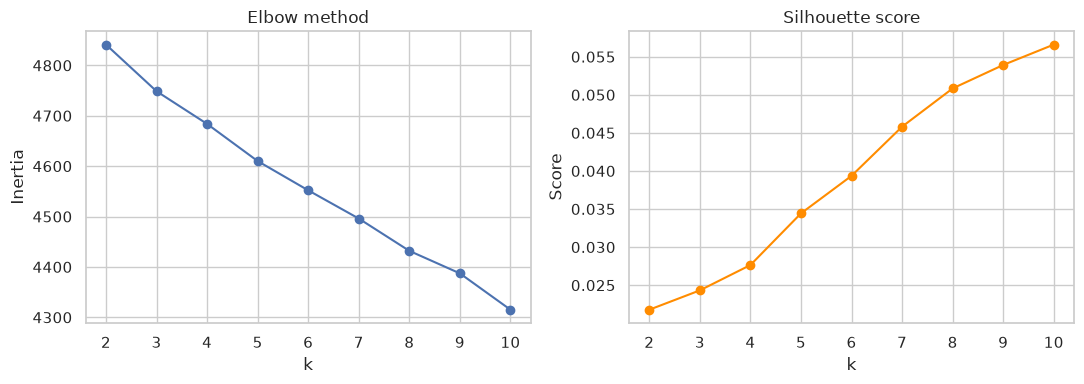

,inertia,silhouette
k,,
2,4841.23,0.0218
3,4748.65,0.0243
4,4683.81,0.0276
5,4610.11,0.0344
6,4552.04,0.0394
7,4496.03,0.0458
8,4431.92,0.0508
9,4387.25,0.0539
10,4315.15,0.0566


In [39]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_lsa)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_lsa, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia")
ax[1].plot(ks, sil, "o-", color="darkorange"); ax[1].set(title="Silhouette score", xlabel="k", ylabel="Score")
plt.tight_layout(); plt.savefig("output/figures/kmeans_k_selection.png", dpi=150); plt.show()
pd.DataFrame({"k": list(ks), "inertia": np.round(inertia, 2), "silhouette": np.round(sil, 4)}).set_index("k")


### Choosing k
The experiment above reports inertia and silhouette for k=2 through 10.
We retain the team's **k=2** as an interpretable two-topic hypothesis:
promotional messages versus personal conversation. Labels are not supplied
to K-Means fitting; they are used afterwards to examine agreement.
This choice is based on interpretability, not a claim that k=2 maximizes silhouette.
Read the actual top terms, plots and scores before describing the clusters.


In [40]:
K = 2  # chosen for interpretability (see explanation above)


## 2.3 Final K-Means model: cluster sizes & silhouette


In [41]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_lsa)
df["cluster"] = km.labels_

sizes = df["cluster"].value_counts().sort_index().rename("n_records").to_frame()
sizes["share_%"] = (sizes["n_records"] / len(df) * 100).round(1)
display(sizes)
print("Silhouette score (full data): %.4f" % silhouette_score(X_lsa, km.labels_))


,n_records,share_%
cluster,,
0,4415,85.5
1,751,14.5


Silhouette score (full data): 0.0211


## 2.4 Distinctive words per cluster
For each cluster the terms with the highest **average TF-IDF weight** among its messages are listed.


In [42]:
terms_all = np.array(tfidf_all.get_feature_names_out())
top_terms = {}
for c in range(K):
    mean_tfidf = np.asarray(X_all[(df["cluster"] == c).values].mean(axis=0)).ravel()
    top_terms[f"Cluster {c}"] = terms_all[np.argsort(mean_tfidf)[::-1][:12]]
top_terms_df = pd.DataFrame(top_terms); top_terms_df.index = range(1, 13)
top_terms_df.to_csv("output/cluster_top_terms.csv")
top_terms_df


,Cluster 0,Cluster 1
1,im,ur
2,ok,free
3,just,txt
4,come,stop
5,dont,mobile
6,got,reply
7,good,text
8,like,claim
9,know,prize
10,time,cash


## 2.5 Clusters vs. original labels


label,ham,spam,total,spam_%
cluster,,,,
0,4306,109,4415,2.5
1,207,544,751,72.4


Purity: 0.939 | Adjusted Rand Index: 0.681 | NMI: 0.491
Baseline purity (always predict 'ham'): 0.874


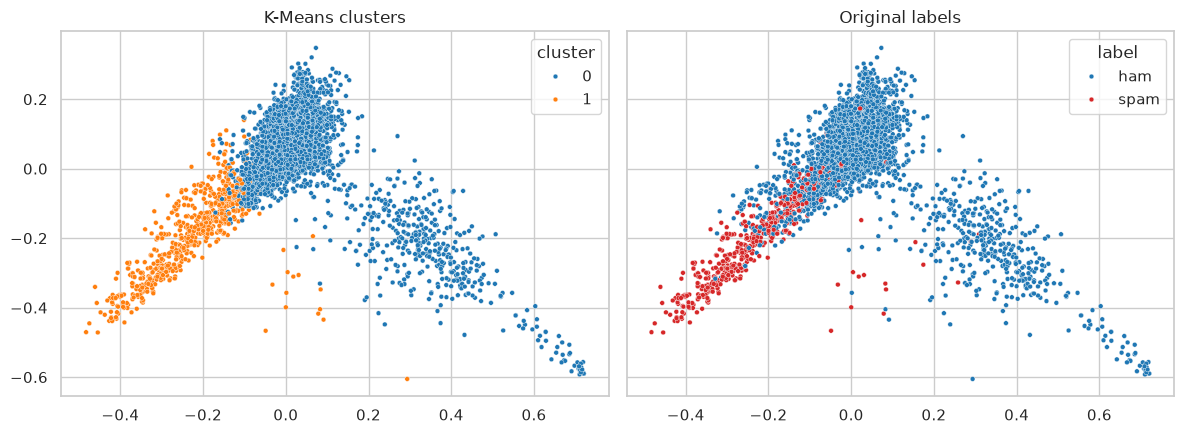

In [43]:
ct = pd.crosstab(df["cluster"], df["label"]); ct["total"] = ct.sum(axis=1)
ct["spam_%"] = (ct["spam"] / ct["total"] * 100).round(1)
display(ct)

purity = pd.crosstab(df["cluster"], df["label"]).max(axis=1).sum() / len(df)
ari = adjusted_rand_score(df["label"], df["cluster"])
nmi = normalized_mutual_info_score(df["label"], df["cluster"])
print(f"Purity: {purity:.3f} | Adjusted Rand Index: {ari:.3f} | NMI: {nmi:.3f}")
print(f"Baseline purity (always predict 'ham'): {1 - df['y'].mean():.3f}")

# Visualise in 2D
pts = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_lsa)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=df["cluster"].astype(str), s=12, ax=ax[0], palette="tab10"); ax[0].set_title("K-Means clusters")
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=df["label"], s=12, ax=ax[1], palette={"ham": "tab:blue", "spam": "tab:red"}); ax[1].set_title("Original labels")
plt.tight_layout(); plt.savefig("output/figures/kmeans_clusters_pca.png", dpi=150); plt.show()


In [44]:
silhouette = silhouette_score(X_lsa, km.labels_)
summary = [
    f"K-Means with k={K}, random_state={RANDOM_STATE}",
    "Representation: TF-IDF -> 100-component TruncatedSVD -> L2 normalization",
    "Reason for k: interpretable two-topic hypothesis; not automatically the silhouette optimum.",
    "", "Cluster sizes:", sizes.to_string(),
    "", f"Silhouette score: {silhouette:.4f}",
    f"Purity: {purity:.4f}; ARI: {ari:.4f}; NMI: {nmi:.4f}",
    "", "Cluster vs original label:", ct.to_string(),
    "", "Top terms:", top_terms_df.to_string(),
    "", "Interpretation:"
]
for c in range(K):
    n = int(sizes.loc[c, "n_records"])
    spam_share = float(ct.loc[c, "spam_%"])
    largest_group = "spam" if spam_share >= 50 else "ham"
    words = ", ".join(top_terms[f"Cluster {c}"][:8])
    summary.append(
        f"Cluster {c}: {n} messages, {spam_share:.1f}% spam; "
        f"majority label is {largest_group}. Top words: {words}. "
        "These describe vocabulary groupings; cluster IDs are not class IDs."
    )
summary.append(
    "Silhouette measures geometric separation; label agreement measures something "
    "different. Overlapping short-message vocabulary can give a low silhouette "
    "even when clusters agree with known labels."
)
report = "\n".join(summary)
print(report)
(OUTPUT / "cluster_summary.txt").write_text(report, encoding="utf-8")


K-Means with k=2, random_state=42
Representation: TF-IDF -> 100-component TruncatedSVD -> L2 normalization
Reason for k: interpretable two-topic hypothesis; not automatically the silhouette optimum.

Cluster sizes:
         n_records  share_%
cluster                    
0             4415     85.5
1              751     14.5

Silhouette score: 0.0211
Purity: 0.9388; ARI: 0.6806; NMI: 0.4910

Cluster vs original label:
label     ham  spam  total  spam_%
cluster                           
0        4306   109   4415     2.5
1         207   544    751    72.4

Top terms:
   Cluster 0 Cluster 1
1         im        ur
2         ok      free
3       just       txt
4       come      stop
5       dont    mobile
6        got     reply
7       good      text
8       like     claim
9       know     prize
10      time      cash
11       ill       won
12     going   contact

Interpretation:
Cluster 0: 4415 messages, 2.5% spam; majority label is ham. Top words: im, ok, just, come, dont, got, good, li

1455

## Final output check
Required deliverables must exist on the host through the `output/` bind mount.
The executed notebook is also saved to `output/` when you use the documented
command-line execution; in JupyterLab, save/download the executed notebook too.


In [45]:
import subprocess
import sys

(OUTPUT / "environment_requirements.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True),
    encoding="utf-8"
)
required = ["cleaned_data.csv", "model_metrics.txt", "cluster_summary.txt"]
for name in required:
    path = OUTPUT / name
    assert path.is_file() and path.stat().st_size > 0, f"Missing output: {name}"
    print("OK:", name)
figures = sorted(FIGURES.glob("*.png"))
assert len(figures) >= 4, "At least four figures are required."
for path in figures:
    print("Figure:", path.name)
print("ALL REQUIRED OUTPUT CHECKS PASSED")


OK: cleaned_data.csv
OK: model_metrics.txt
OK: cluster_summary.txt
Figure: average_text_length.png
Figure: average_word_count.png
Figure: confusion_matrices.png
Figure: correlation_heatmap.png
Figure: kmeans_clusters_pca.png
Figure: kmeans_k_selection.png
Figure: sampling_comparison.png
Figure: top_20_words.png
Figure: top_20_words_without_stopwords.png
ALL REQUIRED OUTPUT CHECKS PASSED
